### Loan Prediction Model

**Aim:** 

#### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,f1_score,accuracy_score,classification_report

from imblearn.over_sampling import SMOTE 


#### Load And Inspect Dataset

In [2]:
ds = pd.read_csv('loan_approval_dataset.csv')
ds.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [3]:
#summary statistics
ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 531.6 KB


In [4]:
ds.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [5]:
#check for missing cells
ds.isna().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

#### Visualizing the Collinearity of the DS

<Axes: >

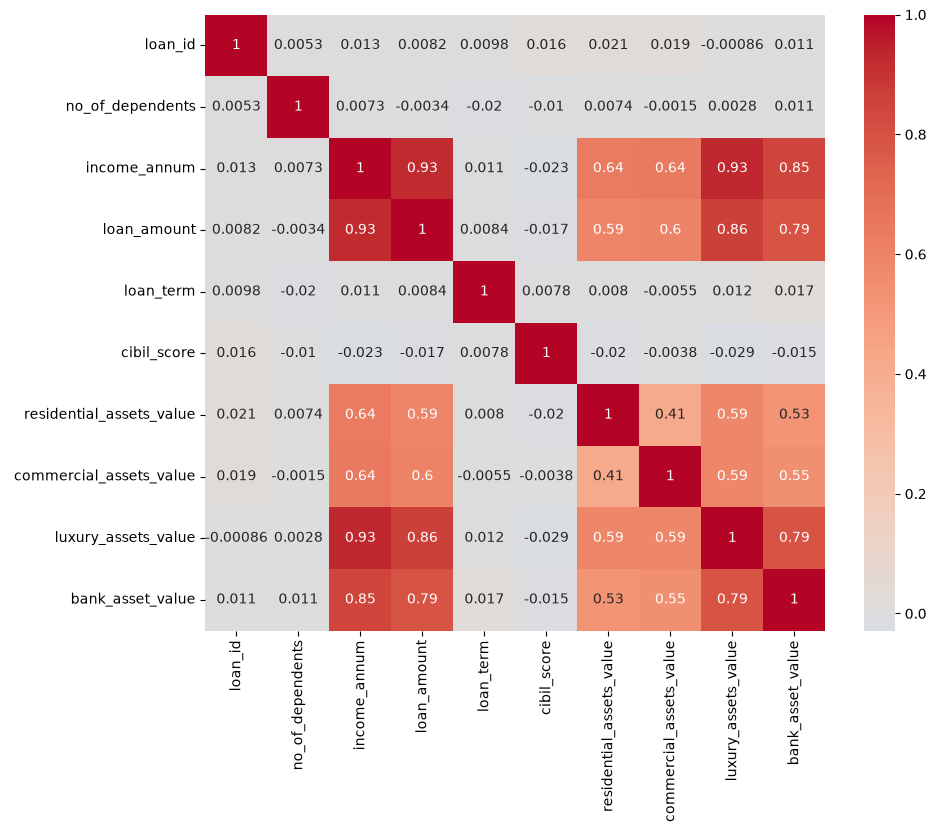

In [6]:
plt.figure(figsize=(10,8))
cols = ds.select_dtypes(include=[np.number]).columns
sns.heatmap(ds[cols].corr(), annot = True, center =0, cmap='coolwarm')

In [7]:
#inspecting features
ds.columns.tolist()


['loan_id',
 ' no_of_dependents',
 ' education',
 ' self_employed',
 ' income_annum',
 ' loan_amount',
 ' loan_term',
 ' cibil_score',
 ' residential_assets_value',
 ' commercial_assets_value',
 ' luxury_assets_value',
 ' bank_asset_value',
 ' loan_status']

In [8]:
# remove white spaces in columnn string names
ds.columns = ds.columns.str.strip()

#remove extra spaces in string inside column
for col in ds.select_dtypes(include=['object','str']).columns:
    ds[col] =ds[col].str.strip()
ds.columns.tolist()


['loan_id',
 'no_of_dependents',
 'education',
 'self_employed',
 'income_annum',
 'loan_amount',
 'loan_term',
 'cibil_score',
 'residential_assets_value',
 'commercial_assets_value',
 'luxury_assets_value',
 'bank_asset_value',
 'loan_status']

#### Select Features

In [9]:
X = ds.drop(columns = ['loan_status','loan_id'])
y =ds['loan_status']


#### Split Data Set

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify=y)

#### Encode Categorical columns

In [12]:
#Binary mapping
X_train['education']=X_train['education'].map({'Graduate':1,'Not Graduate':0})
X_test['education'] = X_test['education'].map({'Graduate':1,'Not Graduate':0})
X_train['self_employed'] = X_train['self_employed'].map({'Yes':1,'No':0})
X_test['self_employed'] = X_test['self_employed'].map({'Yes':1,'No':0})

In [13]:
# Map target variable
y_train = y_train.map({'Approved': 1, 'Rejected': 0})
y_test = y_test.map({'Approved': 1, 'Rejected': 0})


In [14]:
print(X_train.isna().sum())
print(X_test.isna().sum())
print(X_train.dtypes)
print()
print(y_train.unique())
print(y_test.unique())
print(y_train.isna().sum())
print(y_test.isna().sum())

no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
dtype: int64
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
dtype: int64
no_of_dependents            int64
education                   int64
self_employed               int64
income_annum                int64
loan_amount                 int64
loan_term                   int64
cibil_score                 int64
residential_assets_value    int64
commercial_assets_value     int64
luxury_a

#### Scaling The Training Data

In [15]:
scaler = StandardScaler()
X_train_scaled =scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


##### Using SMOTE to Curb Class Imbalance

In [16]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

#### **Logistic Regression Training**

* Train Data On Scaled Features

In [17]:
model = LogisticRegression(max_iter=300)
model.fit(X_train_resampled,y_train_resampled)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",300
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'l

* Making Predictions

In [18]:
y_pred = model.predict(X_test_scaled)


* Comparing Actual Values and Predicted Values

In [19]:
cmp_table = pd.DataFrame({'Actual Values':y_test,'Prediction':y_pred})
cmp_table['Actual Values']= cmp_table['Actual Values'].map({1:'Approved',0:'Rejected'})
cmp_table['Prediction']=cmp_table['Prediction'].map({1:'Approved',0:'Rejected'})
cmp_table



,Actual Values,Prediction
2346,Approved,Approved
1162,Approved,Approved
3061,Approved,Approved
483,Rejected,Approved
2102,Approved,Approved
...,...,...
1040,Approved,Approved
3069,Rejected,Rejected
3920,Approved,Approved
119,Approved,Approved


## **Evaluation**

* Classification Report

In [20]:
class_report = classification_report(y_test,y_pred)
print(class_report)

              precision    recall  f1-score   support

           0       0.91      0.91      0.91       323
           1       0.95      0.94      0.95       531

    accuracy                           0.93       854
   macro avg       0.93      0.93      0.93       854
weighted avg       0.93      0.93      0.93       854



* Accuracy Score

In [21]:
acc_score = accuracy_score(y_test, y_pred)
print(f"Accuracy Score of The Model is :{round(acc_score *100)}%")

Accuracy Score of The Model is :93%


* Confusion Matrix

In [22]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[295  28]
 [ 30 501]]


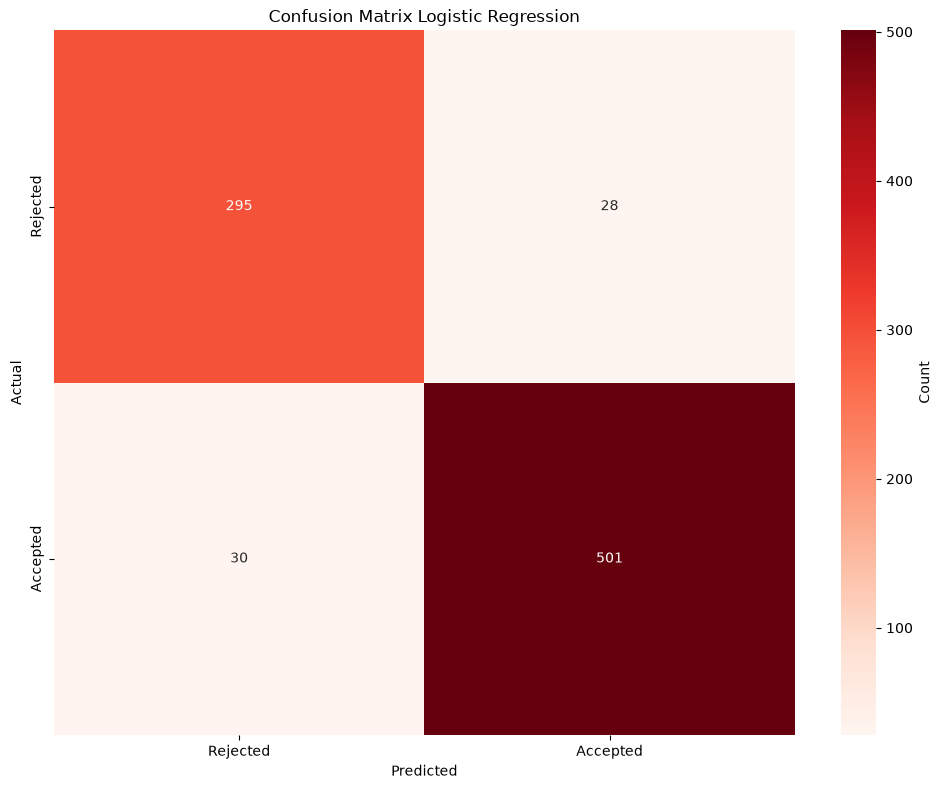

In [23]:
#visualize confusion matrix

plt.figure(figsize=(10,8))
#sort predictions 
loan_status =['Rejected','Accepted']
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=loan_status,
            yticklabels=loan_status,
            cbar_kws={'label': 'Count'})
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title(f'Confusion Matrix Logistic Regression')
plt.tight_layout()
plt.show()

### DECISION TREE MODEL

In [24]:
from sklearn.tree import DecisionTreeClassifier


In [25]:
#train model
dt_model = DecisionTreeClassifier(
    random_state=42,
    splitter='best',
    criterion='entropy',
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    )


In [26]:
dt_model.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [27]:
dt_prediction = dt_model.predict(X_test)


In [28]:
class_report2 = classification_report(y_test,dt_prediction)
print(class_report2)

              precision    recall  f1-score   support

           0       0.99      0.96      0.98       323
           1       0.98      0.99      0.99       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



In [29]:
cm2 = confusion_matrix(y_test,dt_prediction)
cm2

array([[311,  12],
       [  3, 528]])

Text(0.5, 80.38563368055553, 'Decision Tree Predicted value')

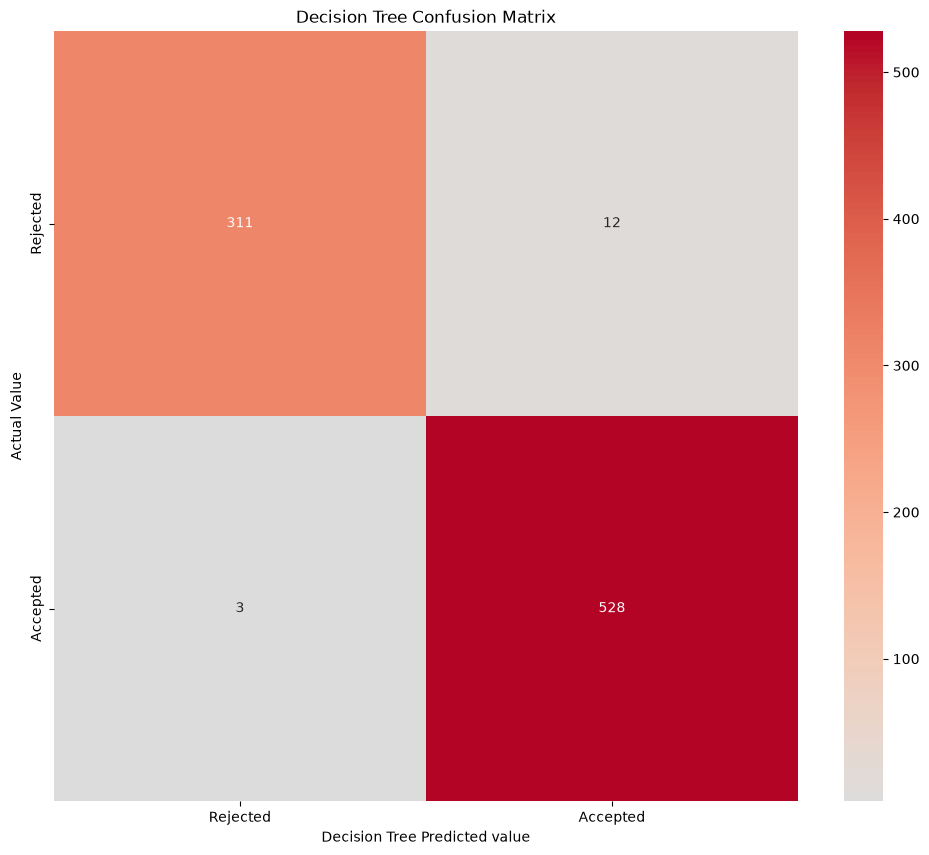

In [30]:
plt.figure(figsize=(12,10))
plt.title('Decision Tree Confusion Matrix')
sns.heatmap(cm2,
    center =0,
    fmt ='d',
    cmap='coolwarm',
    annot =True,
    xticklabels=loan_status,
    yticklabels=loan_status
    )
plt.ylabel('Actual Value')
plt.xlabel('Decision Tree Predicted value')

In [31]:
acc_score2 =accuracy_score(y_test,dt_prediction)
acc_score2

0.9824355971896955

* check for over fitting

In [32]:
#inspect model behaviour with training data
dt_train_pred = dt_model.predict(X_train)
accuracy_score(y_train,dt_train_pred)

0.986822840409956

#### **Saving Model**

In [33]:
import joblib

#create a dictionary of the exact model, preprocessing and attributes
model_artifact = {
    'model': dt_model, 
    'feature_names': X.columns.tolist(),
    'education_mapping': {'Graduate': 1, 'Not Graduate': 0},
    'self_employed_mapping': {'Yes': 1, 'No': 0},
    'target_mapping': {1: 'Approved', 0: 'Rejected'}
}

joblib.dump(model_artifact, 'loan_approval_model.joblib')

['loan_approval_model.joblib']

In [34]:
#load joblib file
loaded_artifact = joblib.load('loan_approval_model.joblib')

loaded_model = loaded_artifact['model']
feature_names = loaded_artifact['feature_names']

print("Model loaded:", type(loaded_model).__name__)
print("Number of features:", len(feature_names))

Model loaded: DecisionTreeClassifier
Number of features: 11


In [35]:
#create sample data
applicant = {
    'no_of_dependents': 0,
    'education': 'Not Graduate',
    'self_employed': 'Yes',
    'income_annum': 4100000,
    'loan_amount': 12200,
    'loan_term': 9,
    'cibil_score': 417,
    'residential_assets_value':2700000,
    'commercial_assets_value':2200000,
    'luxury_assets_value':8800000,
    'bank_asset_value':  3300000
}

#duate	Yes	4100000	12200000	8	417	2700000	2200000	8800000	3300000	Rejected

In [36]:
applicant_df = pd.DataFrame([applicant])

In [37]:
#encode applicant categorical features from the model's preprocessing 
applicant_df['education'] = applicant_df['education'].map(loaded_artifact['education_mapping'])

applicant_df['self_employed'] = applicant_df['self_employed'].map(loaded_artifact['self_employed_mapping'])

In [38]:
print(applicant_df[['education', 'self_employed']])

   education  self_employed
0          0              1


In [39]:
applicant_df = applicant_df[feature_names]

print(applicant_df.columns.tolist())

['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']


In [45]:
prediction = loaded_model.predict(applicant_df)

print(f"loan status : {prediction}")

loan status : [0]


In [41]:
def predict_loan(applicant):

    applicant_df = pd.DataFrame([applicant])

    # Encode categorical features
    applicant_df['education'] = applicant_df['education'].map(
        loaded_artifact['education_mapping']
    )

    applicant_df['self_employed'] = applicant_df['self_employed'].map(
        loaded_artifact['self_employed_mapping']
    )

    # Arrange features
    applicant_df = applicant_df[feature_names]

    # Predict
    prediction = loaded_model.predict(applicant_df)

    # Convert prediction to readable output
    result = loaded_artifact['target_mapping'][prediction[0]]

    return f"loan status : {result}"

In [ ]:
#test function with new data

another_applicant = {
    'no_of_dependents': 1,
    'education': 'Not Graduate',
    'self_employed': 'Yes',
    'income_annum': 3000000,
    'loan_amount': 20000000,
    'loan_term': 10,
    'cibil_score': 550,
    'residential_assets_value': 2000000,
    'commercial_assets_value': 1000000,
    'luxury_assets_value': 1500000,
    'bank_asset_value': 1000000
}

In [43]:
predict_loan(another_applicant)

'loan status : Approved'